In [1]:
import pandas as pd
df = pd.read_excel("Dataset/Sample - Superstore.xls")
df.head()

ImportError: `Import xlrd` failed. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install the xlrd package.

In [2]:
%pip install xlrd

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
df = pd.read_excel("Dataset/Sample - Superstore.xls")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
print("Dataset Shape:", df.shape)
df.info()

Dataset Shape: (9994, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Ca

In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Records:", df.duplicated().sum())

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
Duplicate Records: 0


In [6]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


In [7]:
print("Total Sales:", df['Sales'].sum())
print("Total Profit:", df['Profit'].sum())
print("Total Quantity Sold:", df['Quantity'].sum())
print("Total Orders:", df['Order ID'].nunique())
print("Average Discount:", df['Discount'].mean())

Total Sales: 2297200.8603
Total Profit: 286397.0216999999
Total Quantity Sold: 37873
Total Orders: 5009
Average Discount: 0.1562027216329798


In [8]:
category_analysis = df.groupby('Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).round(2)

category_analysis

,Sales,Profit,Quantity
Category,,,
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906
Technology,836154.03,145454.95,6939


In [9]:
df.groupby('Product Name')['Profit'].sum().sort_values(ascending=False).head(10)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64

In [10]:
df.groupby('Region')[['Sales', 'Profit']].sum().round(2).sort_values(by='Sales', ascending=False)

,Sales,Profit
Region,,
West,725457.82,108418.45
East,678781.24,91522.78
Central,501239.89,39706.36
South,391721.90,46749.43


In [11]:
df['Month'] = df['Order Date'].dt.month_name()

monthly_sales = df.groupby('Month')['Sales'].sum().sort_values(ascending=False)

monthly_sales.round(2)

Month
November     352461.07
December     325293.50
September    307649.95
March        205005.49
October      200322.98
August       159044.06
May          155028.81
June         152718.68
July         147238.10
April        137762.13
January       94924.84
February      59751.25
Name: Sales, dtype: float64

In [12]:
df.groupby(df['Order Date'].dt.year)['Sales'].sum().round(2)

Order Date
2014    484247.50
2015    470532.51
2016    609205.60
2017    733215.26
Name: Sales, dtype: float64

In [13]:
yearly_analysis = df.groupby(df['Order Date'].dt.year).agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).round(2)

yearly_analysis

,Sales,Profit,Order ID
Order Date,,,
2014,484247.50,49543.97,969
2015,470532.51,61618.60,1038
2016,609205.60,81795.17,1315
2017,733215.26,93439.27,1687


In [14]:
df.groupby('Sub-Category')['Profit'].sum().sort_values().round(2)

Sub-Category
Tables        -17725.48
Bookcases      -3472.56
Supplies       -1189.10
Fasteners        949.52
Machines        3384.76
Labels          5546.25
Art             6527.79
Envelopes       6964.18
Furnishings    13059.14
Appliances     18138.01
Storage        21278.83
Chairs         26590.17
Binders        30221.76
Paper          34053.57
Accessories    41936.64
Phones         44515.73
Copiers        55617.82
Name: Profit, dtype: float64

In [15]:
df['Discount_Band'] = pd.cut(df['Discount'], bins=[-0.01, 0, 0.1, 0.2, 0.3, 0.4, 1], labels=['No Discount', '1-10%', '10-20%', '20-30%', '30-40%', '40%+'])

df.groupby('Discount_Band', observed=True).agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).round(2)

,Sales,Profit,Quantity
Discount_Band,,,
No Discount,1087908.47,320987.60,18267
1-10%,54369.35,9029.18,373
10-20%,792152.89,91756.30,13858
20-30%,103226.66,-10369.28,849
30-40%,130911.24,-25448.19,891
40%+,128632.25,-99558.59,3635


In [16]:
df.groupby('Segment').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique',
    'Customer ID': 'nunique'
}).round(2)

,Sales,Profit,Order ID,Customer ID
Segment,,,,
Consumer,1161401.34,134119.21,2586,409
Corporate,706146.37,91979.13,1514,236
Home Office,429653.15,60298.68,909,148


In [17]:
df.groupby('Customer Name').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).sort_values(by='Sales', ascending=False).head(10).round(2)

,Sales,Profit
Customer Name,,
Sean Miller,25043.05,-1980.74
Tamara Chand,19052.22,8981.32
Raymond Buch,15117.34,6976.10
Tom Ashbrook,14595.62,4703.79
Adrian Barton,14473.57,5444.81
Ken Lonsdale,14175.23,806.85
Sanjit Chand,14142.33,5757.41
Hunter Lopez,12873.30,5622.43
Sanjit Engle,12209.44,2650.68


In [18]:
df['Shipping_Days'] = (df['Ship Date'] - df['Order Date']).dt.days

df.groupby('Ship Mode').agg({
    'Shipping_Days': 'mean',
    'Order ID': 'nunique',
    'Sales': 'sum'
}).round(2).sort_values(by='Shipping_Days')

,Shipping_Days,Order ID,Sales
Ship Mode,,,
Same Day,0.04,264,128363.12
First Class,2.18,787,351428.42
Second Class,3.24,964,459193.57
Standard Class,5.01,2994,1358215.74


In [19]:
monthly_trend = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum()

plt.figure(figsize=(14, 6))
plt.plot(monthly_trend.index.astype(str), monthly_trend.values,
         marker='o', linewidth=2)

plt.title('Monthly Sales Trend (2014–2017)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [20]:
import matplotlib.pyplot as plt

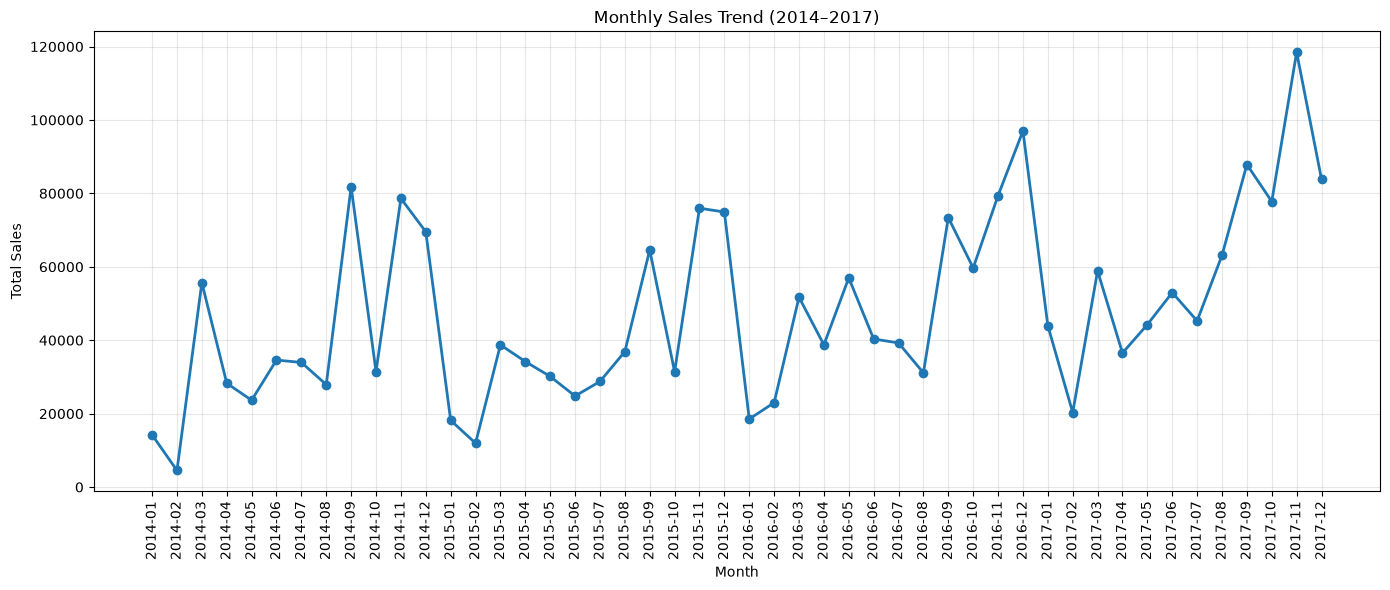

In [21]:
monthly_trend = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum()

plt.figure(figsize=(14, 6))
plt.plot(monthly_trend.index.astype(str), monthly_trend.values,
         marker='o', linewidth=2)

plt.title('Monthly Sales Trend (2014–2017)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

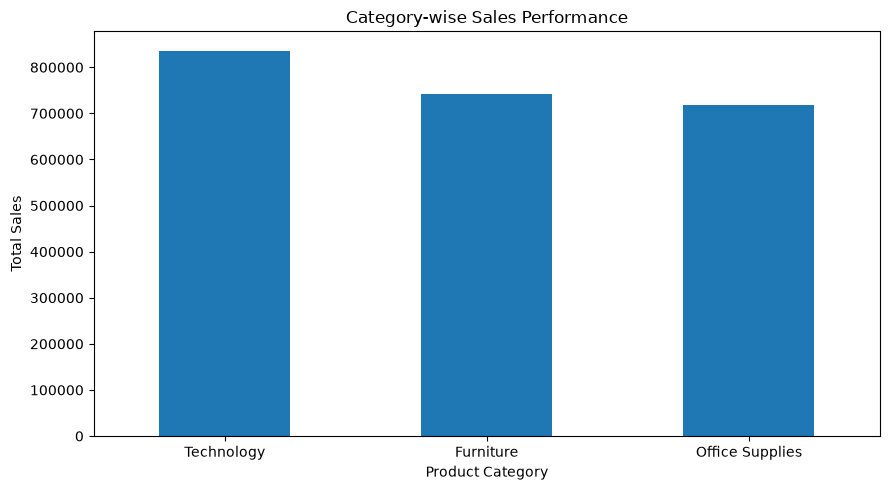

In [22]:
category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
category_sales.plot(kind='bar', title='Category-wise Sales Performance')

plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

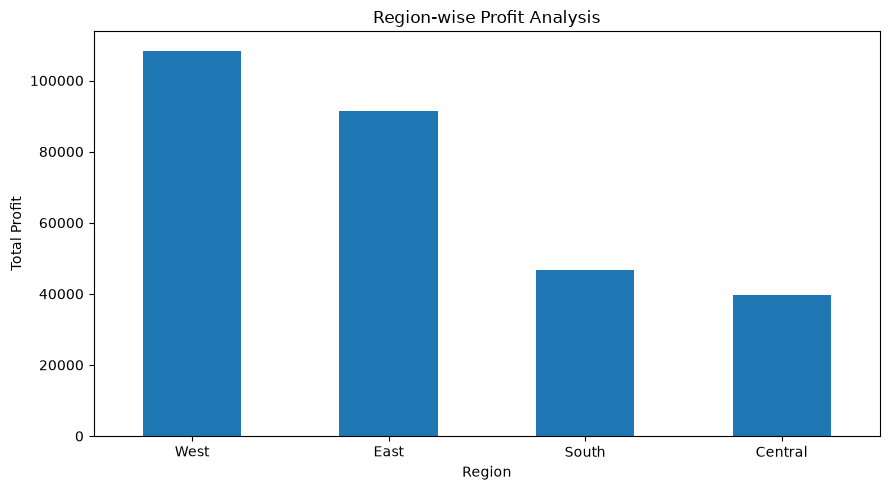

In [23]:
region_profit = df.groupby('Region')['Profit'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
region_profit.plot(kind='bar', title='Region-wise Profit Analysis')

plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

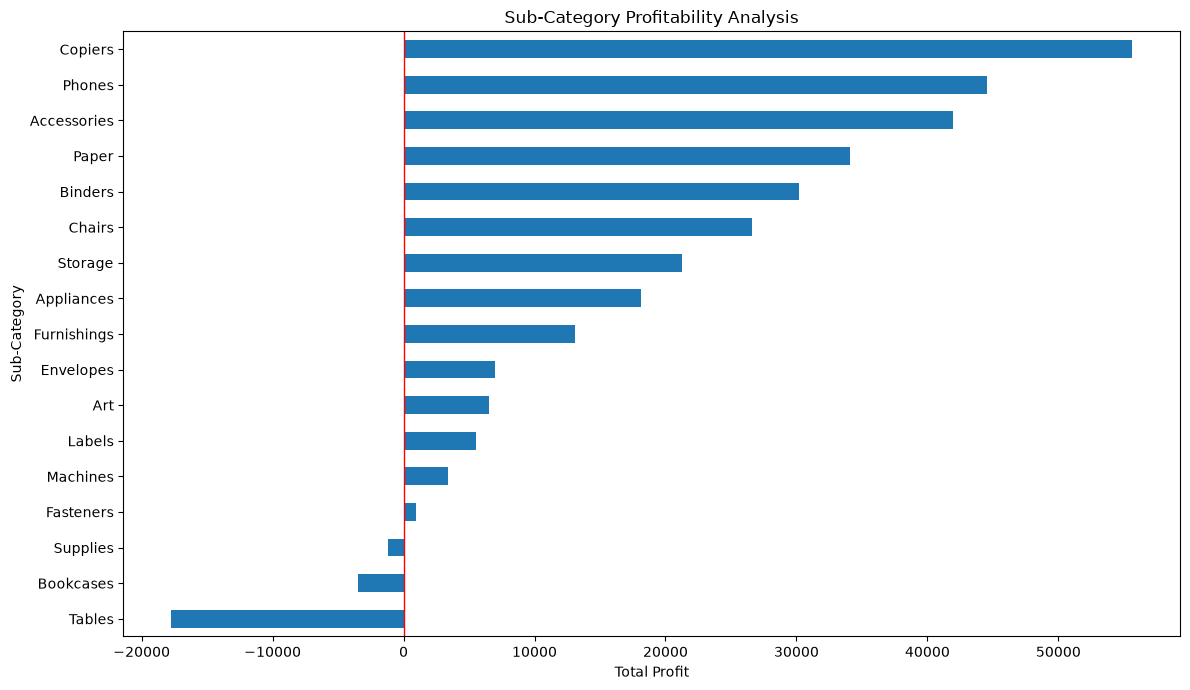

In [24]:
subcategory_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values()

plt.figure(figsize=(12, 7))
subcategory_profit.plot(kind='barh', title='Sub-Category Profitability Analysis')

plt.xlabel('Total Profit')
plt.ylabel('Sub-Category')
plt.axvline(x=0, color='red', linewidth=1)
plt.tight_layout()
plt.show()

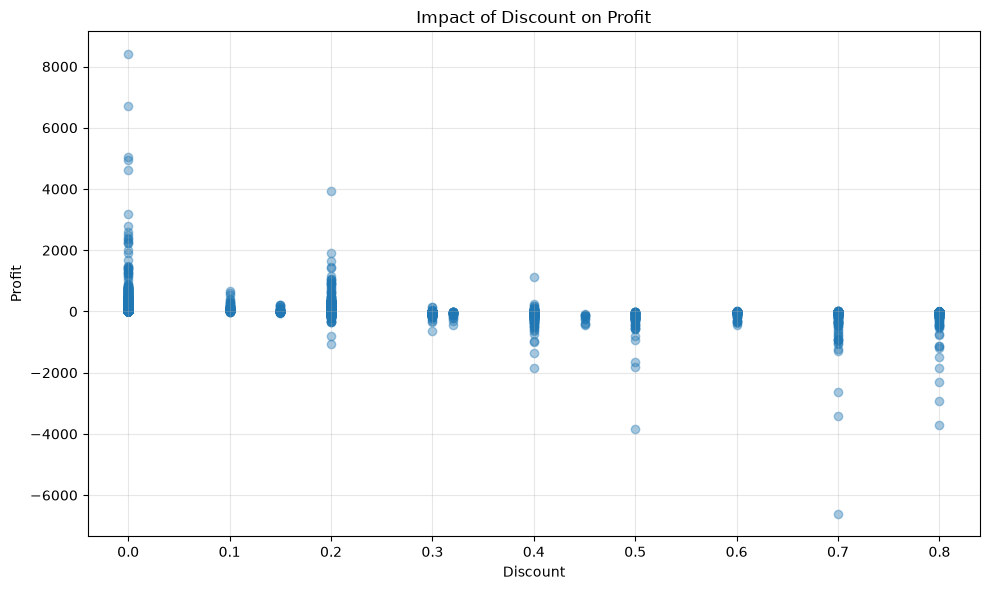

In [25]:
plt.figure(figsize=(10, 6))

plt.scatter(df['Discount'], df['Profit'], alpha=0.4)

plt.title('Impact of Discount on Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
kpi_summary = pd.DataFrame({
    'Metric': [
        'Total Revenue',
        'Total Profit',
        'Total Orders',
        'Total Quantity Sold',
        'Average Order Value',
        'Profit Margin',
        'Average Discount'
    ],
    'Value': [
        df['Sales'].sum(),
        df['Profit'].sum(),
        df['Order ID'].nunique(),
        df['Quantity'].sum(),
        df['Sales'].sum() / df['Order ID'].nunique(),
        (df['Profit'].sum() / df['Sales'].sum()) * 100,
        df['Discount'].mean() * 100
    ]
})

kpi_summary.round(2)

,Metric,Value
0,Total Revenue,2297200.86
1,Total Profit,286397.02
2,Total Orders,5009.00
3,Total Quantity Sold,37873.00
4,Average Order Value,458.61
5,Profit Margin,12.47
6,Average Discount,15.62


In [27]:
category_performance = df.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

category_performance['Profit_Margin_%'] = (
    category_performance['Total_Profit'] /
    category_performance['Total_Sales'] * 100
)

category_performance.round(2)

,Total_Sales,Total_Profit,Profit_Margin_%
Category,,,
Furniture,741999.80,18451.27,2.49
Office Supplies,719047.03,122490.80,17.04
Technology,836154.03,145454.95,17.40


In [28]:
monthly_mis = df.groupby(
    df['Order Date'].dt.to_period('M')
).agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order ID', 'nunique'),
    Quantity_Sold=('Quantity', 'sum')
)

monthly_mis.round(2)

,Revenue,Profit,Orders,Quantity_Sold
Order Date,,,,
2014-01,14236.90,2450.19,32,284
2014-02,4519.89,862.31,28,159
2014-03,55691.01,498.73,71,585
2014-04,28295.34,3488.84,66,536
2014-05,23648.29,2738.71,69,466
2014-06,34595.13,4976.52,66,521
2014-07,33946.39,-841.48,65,550
2014-08,27909.47,5318.10,72,609
2014-09,81777.35,8328.10,130,1000


In [29]:
print("Negative Sales:", (df['Sales'] < 0).sum())
print("Zero or Negative Quantity:", (df['Quantity'] <= 0).sum())
print("Invalid Discounts:", (~df['Discount'].between(0, 1)).sum())
print("Invalid Shipping Dates:", (df['Ship Date'] < df['Order Date']).sum())

Negative Sales: 0
Zero or Negative Quantity: 0
Invalid Discounts: 0
Invalid Shipping Dates: 0


In [30]:
yearly_sales = df.groupby(
    df['Order Date'].dt.year
)['Sales'].sum()

yoy_growth = yearly_sales.pct_change() * 100

yoy_growth.round(2)

Order Date
2014      NaN
2015    -2.83
2016    29.47
2017    20.36
Name: Sales, dtype: float64

In [31]:
customer_orders = df.groupby('Customer ID')['Order ID'].nunique()

print("Total Customers:", len(customer_orders))
print("Repeat Customers:", (customer_orders > 1).sum())
print("Repeat Customer Rate (%):", round((customer_orders > 1).mean() * 100, 2))

Total Customers: 793
Repeat Customers: 781
Repeat Customer Rate (%): 98.49


In [32]:
customer_orders = df.groupby('Customer ID')['Order ID'].nunique()

print("Total Customers:", len(customer_orders))
print("Repeat Customers:", (customer_orders > 1).sum())
print("Repeat Customer Rate (%):", round((customer_orders > 1).mean() * 100, 2))

Total Customers: 793
Repeat Customers: 781
Repeat Customer Rate (%): 98.49


In [33]:
state_analysis = df.groupby('State').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique')
).sort_values(by='Total_Sales', ascending=False).head(10)

state_analysis.round(2)

,Total_Sales,Total_Profit,Total_Orders
State,,,
California,457687.63,76381.39,1021
New York,310876.27,74038.55,562
Texas,170188.05,-25729.36,487
Washington,138641.27,33402.65,256
Pennsylvania,116511.91,-15559.96,288
Florida,89473.71,-3399.30,200
Illinois,80166.10,-12607.89,276
Ohio,78258.14,-16971.38,236
Michigan,76269.61,24463.19,117


In [34]:
loss_products = df.groupby('Product Name')['Profit'].sum().sort_values().head(10)

loss_products.round(2)


Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.97
Lexmark MX611dhe Monochrome Laser Printer                           -4589.97
Cubify CubeX 3D Printer Triple Head Print                           -3839.99
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.12
Bush Advantage Collection Racetrack Conference Table                -1934.40
GBC DocuBind P400 Electric Binding System                           -1878.17
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.08
Martin Yale Chadless Opener Electric Letter Opener                  -1299.18
Balt Solid Wood Round Tables                                        -1201.06
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.44
Name: Profit, dtype: float64

In [35]:
with pd.ExcelWriter("Reports/Retail_Sales_MIS_Report.xlsx") as writer:
    kpi_summary.to_excel(writer, sheet_name="KPI Summary", index=False)
    category_analysis.to_excel(writer, sheet_name="Category Analysis")
    monthly_mis.to_excel(writer, sheet_name="Monthly MIS")
    state_analysis.to_excel(writer, sheet_name="State Analysis")
    loss_products.to_frame("Total Loss").to_excel(writer, sheet_name="Loss Products")

print("Excel MIS Report created successfully!")

Excel MIS Report created successfully!


In [37]:
import xlrd; print(xlrd.__version__)

2.0.2


In [38]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Month,Discount_Band,Shipping_Days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,November,No Discount,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,November,No Discount,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,June,No Discount,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,October,40%+,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,October,10-20%,7


In [39]:
import matplotlib.pyplot as plt, os
os.makedirs("../Visualizations", exist_ok=True)
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

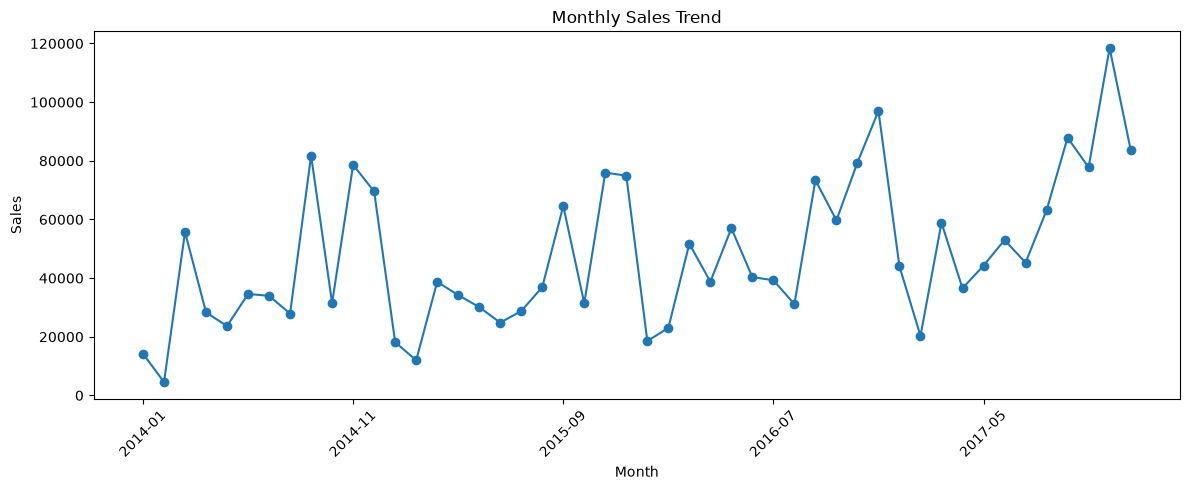

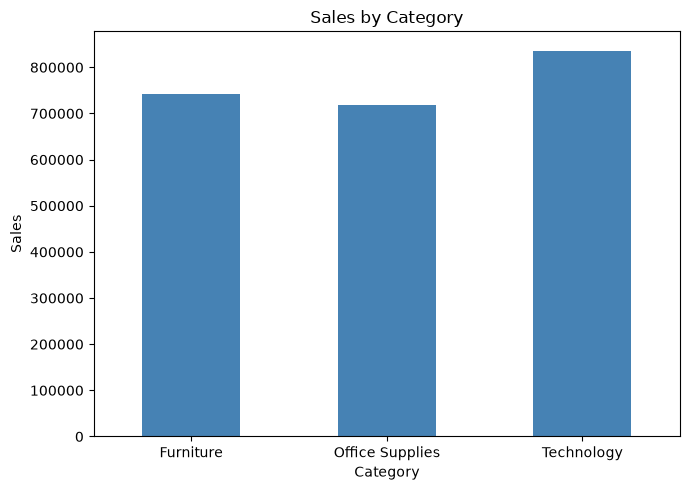

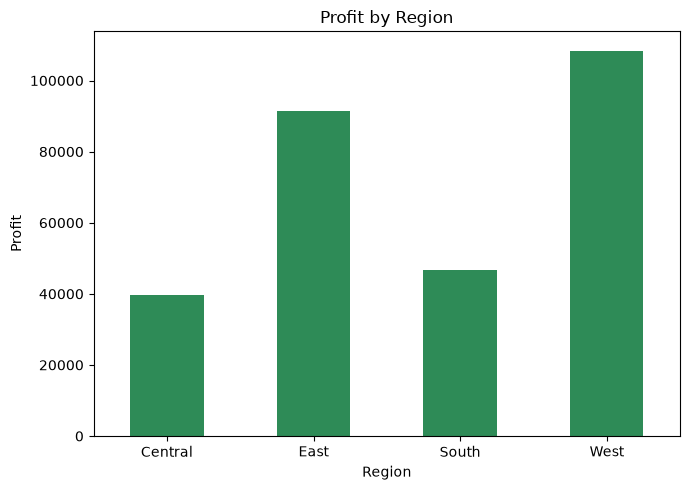

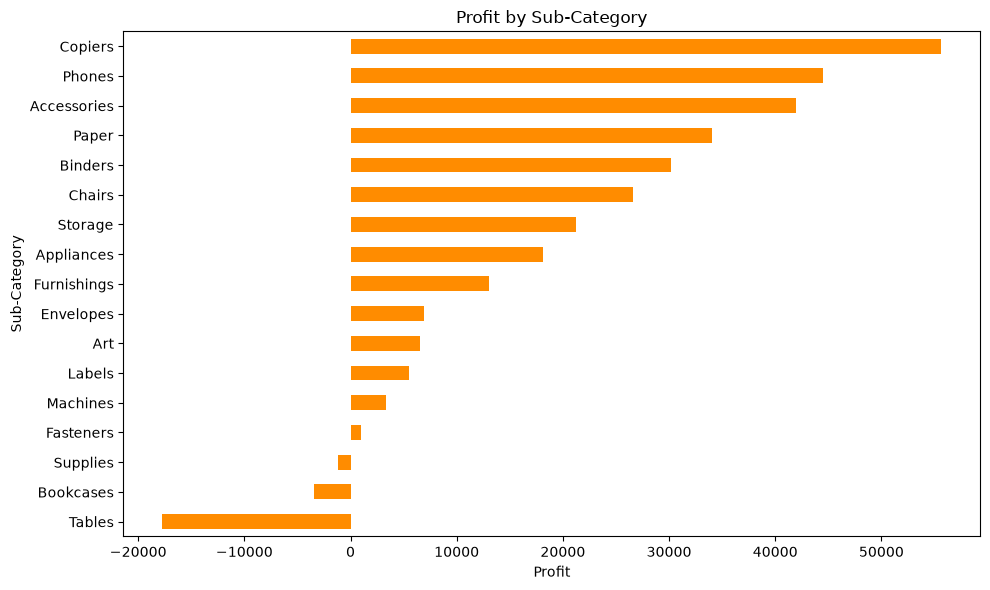

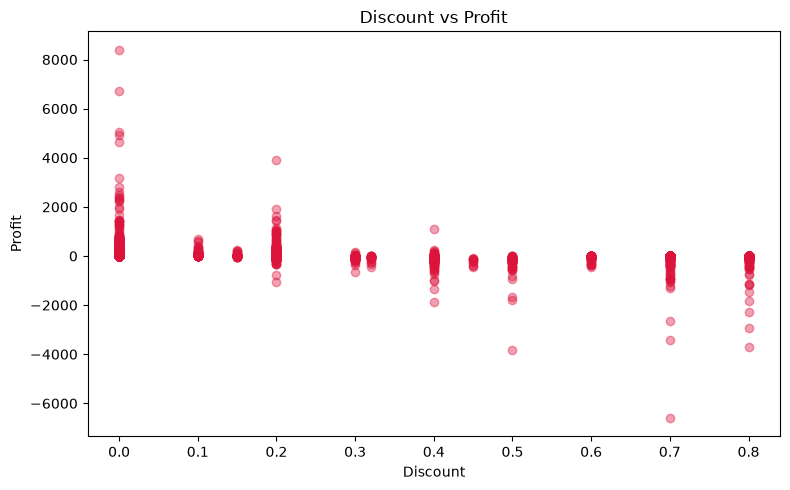

Saved: ['category_sales.png', 'discount_profit.png', 'monthly_sales_trend.png', 'region_profit.png', 'subcategory_profit.png']


In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Change this ONE line to "../Visualizations" after moving the notebook into Notebooks/
OUT = "Visualizations"
DATA = "Dataset/Sample - Superstore.xls"   # use "../Dataset/..." after moving

os.makedirs(OUT, exist_ok=True)
df = pd.read_excel(DATA)
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

# 1. Monthly sales trend
plt.figure(figsize=(12,5))
df.groupby("Month")["Sales"].sum().plot(marker="o")
plt.title("Monthly Sales Trend"); plt.ylabel("Sales"); plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{OUT}/monthly_sales_trend.png", dpi=150)
plt.show()

# 2. Category sales
plt.figure(figsize=(7,5))
df.groupby("Category")["Sales"].sum().plot(kind="bar", color="steelblue")
plt.title("Sales by Category"); plt.ylabel("Sales"); plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{OUT}/category_sales.png", dpi=150)
plt.show()

# 3. Region profit
plt.figure(figsize=(7,5))
df.groupby("Region")["Profit"].sum().plot(kind="bar", color="seagreen")
plt.title("Profit by Region"); plt.ylabel("Profit"); plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{OUT}/region_profit.png", dpi=150)
plt.show()

# 4. Sub-category profit
plt.figure(figsize=(10,6))
df.groupby("Sub-Category")["Profit"].sum().sort_values().plot(kind="barh", color="darkorange")
plt.title("Profit by Sub-Category"); plt.xlabel("Profit")
plt.tight_layout()
plt.savefig(f"{OUT}/subcategory_profit.png", dpi=150)
plt.show()

# 5. Discount vs profit
plt.figure(figsize=(8,5))
plt.scatter(df["Discount"], df["Profit"], alpha=0.4, color="crimson")
plt.title("Discount vs Profit"); plt.xlabel("Discount"); plt.ylabel("Profit")
plt.tight_layout()
plt.savefig(f"{OUT}/discount_profit.png", dpi=150)
plt.show()

print("Saved:", os.listdir(OUT))